# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB (decimal MB, as requested)
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / 1_000_000

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB (1 TB = 1024**4 bytes)
fleet_bytes = 1920 * 1080 * 3 * frames_per_day * 400
fleet_tb = fleet_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps, plus retained pixel percentage
small_frames_per_day = 10 * 24 * 60 * 60
fleet_small_bytes = 640 * 360 * 3 * small_frames_per_day * 400
fleet_tb_small = fleet_small_bytes / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One 1080p RGB frame: {frame_mb:.2f} MB")
print(f"Frames per camera per day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.2f} TB/day")
print(f"Fleet (360p, 10 fps): {fleet_tb_small:,.2f} TB/day")
print(f"Pixels per frame remaining: {pct_pixels_remaining:.2f}%")

One 1080p RGB frame: 6.22 MB
Frames per camera per day: 2,592,000
Fleet (1080p, 30 fps): 5,865.99 TB/day
Fleet (360p, 10 fps): 217.26 TB/day
Pixels per frame remaining: 11.11%


**Reflection:**

Spatial evidence lost: fine details such as a person's face, clothing, or a small object may disappear when each frame is reduced to 640 × 360. Temporal evidence lost: brief actions or transitions between sampled frames can be missed at 10 fps, including a fast hand movement or a short entry/exit event. Interpolation cannot recover details that were never captured.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

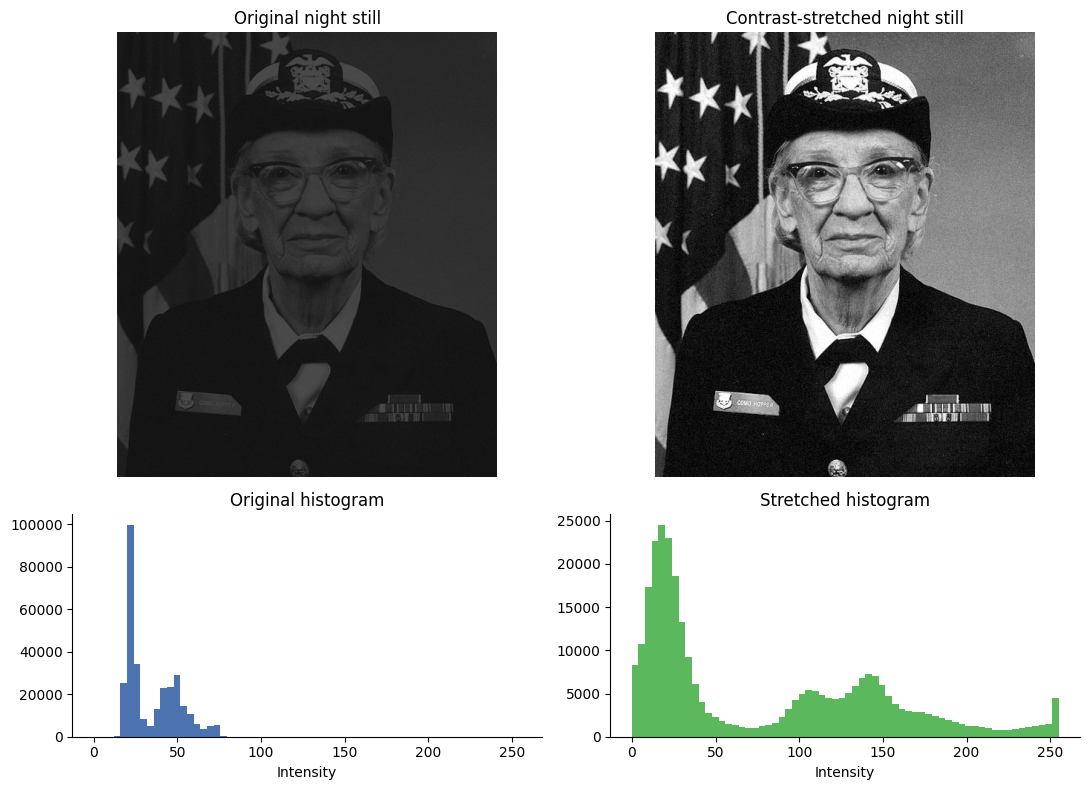

Contrast before: 0.609 -> after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Robust contrast using the 1st and 99th percentiles
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# Map the robust intensity range to 0..255 and clip outliers
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)
s1, s99 = np.percentile(stretched, [1, 99])
c_after = michelson(s99, s1)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original night still")
axes[0, 0].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 0].set_title("Original histogram"); axes[1, 0].set_xlabel("Intensity")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-stretched night still")
axes[0, 1].axis("off")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="#5cb85c")
axes[1, 1].set_title("Stretched histogram"); axes[1, 1].set_xlabel("Intensity")
plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")

**Reflection:**

The original histogram is narrow and concentrated toward the dark end: most pixels occupy a small, low-intensity range, which is the lecture's low-contrast / underexposed pattern. Stretching spreads the occupied values across the display range, making differences between existing pixel intensities easier to see. It changes the mapping, not the underlying scene, so it adds no new information. A histogram discards spatial arrangement; the same intensity distribution could belong to completely different pictures, so it cannot identify objects or tell us what is depicted.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7s to 68.7s
Standing: 68.8s to 68.8s
Standing: 68.9s to 70.5s
Standing: 70.6s to 70.8s
Standing: 70.9s to 71.1s
Standing: 71.2s to 71.6s
Standing: 71.7s to 72.0s
Standing: 72.1s to 72.1s
Standing: 72.2s to 72.7s
Standing: 72.8s to 73.2s
Standing: 73.3s to 73.7s
Standing: 73.8s to 73.9s
Standing: 74.0s to 74.0s
Standing: 74.1s to 74.2s
Standing: 74.3s to 74.7s
Standing: 74.7s to 75.4s
Standing: 75.4s to 75.5s
Standing: 75.5s to 75.6s
Standing: 75.6s to 75.7s
Standing: 75.7s to 75.7s
Standing: 75.8s to 75.9s
Standing: 76.0s to 76.5s
Standing: 76.6s to 76.9s
Standing: 77.0s to 78.1s
Running: 78.6s to 86.0s
First audio > -20 dB: 75.00s
First brightness jump > 40: 100.00s


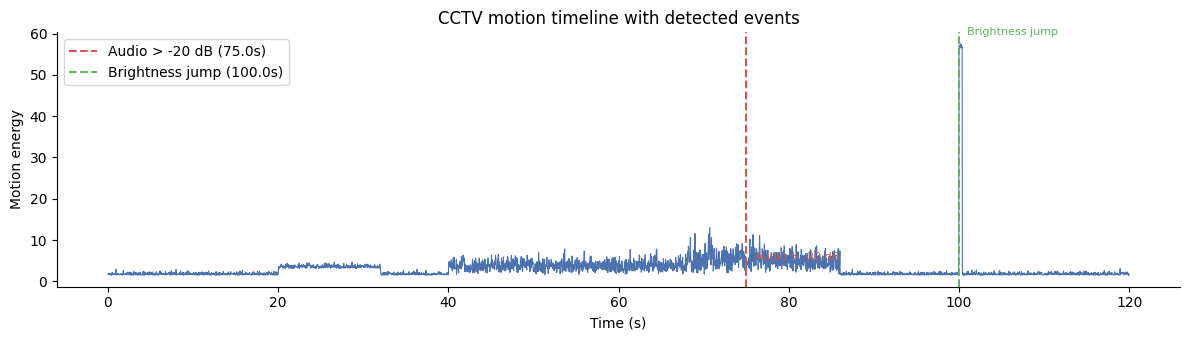

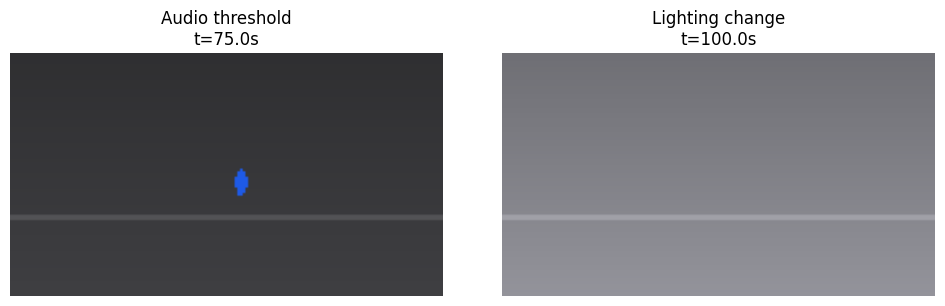

In [4]:
# TODO 1: person speed (px/s), using a 1-second (30-frame) displacement
speed = np.hypot(cctv["person_x"].diff(FPS), cctv["person_y"].diff(FPS))

# TODO 2: contiguous standing / running time ranges
def print_ranges(mask, label):
    mask = mask.fillna(False).to_numpy(dtype=bool)
    edges = np.diff(np.r_[False, mask, False].astype(int))
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    if len(starts) == 0:
        print(f"{label}: none")
    for start, end in zip(starts, ends):
        print(f"{label}: {cctv.time_s.iloc[start]:.1f}s to {cctv.time_s.iloc[min(end-1, len(cctv)-1)]:.1f}s")

print_ranges(speed < 3, "Standing")
print_ranges(speed > 25, "Running")

# TODO 3: first threshold crossings / frame-to-frame lighting jumps
audio_hits = np.flatnonzero(cctv["audio_level_db"].to_numpy() > -20)
audio_event_idx = int(audio_hits[0]) if len(audio_hits) else None
brightness_jump = cctv["mean_brightness"].diff()
lighting_hits = np.flatnonzero(brightness_jump.to_numpy() > 40)
lighting_event_idx = int(lighting_hits[0]) if len(lighting_hits) else None
print("First audio > -20 dB:", None if audio_event_idx is None else f"{cctv.time_s.iloc[audio_event_idx]:.2f}s")
print("First brightness jump > 40:", None if lighting_event_idx is None else f"{cctv.time_s.iloc[lighting_event_idx]:.2f}s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8)
for idx, label, color in [(audio_event_idx, "Audio > -20 dB", "#D9534F"),
                          (lighting_event_idx, "Brightness jump", "#5cb85c")]:
    if idx is not None:
        t_event = cctv.time_s.iloc[idx]
        ax.axvline(t_event, color=color, ls="--", label=f"{label} ({t_event:.1f}s)")
        ax.annotate(label, (t_event, cctv.motion_energy.iloc[idx]),
                    xytext=(6, 8), textcoords="offset points", fontsize=8, color=color)
ax.set(xlabel="Time (s)", ylabel="Motion energy", title="CCTV motion timeline with detected events")
ax.legend(); plt.tight_layout(); plt.show()

# TODO 5: one representative keyframe per detected event
event_indices = [i for i in [audio_event_idx, lighting_event_idx] if i is not None]
if event_indices:
    fig, axes = plt.subplots(1, len(event_indices), figsize=(5 * len(event_indices), 3))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, event_indices):
        ax.imshow(render_frame(cctv.iloc[i]))
        ax.set_title(f"{'Audio threshold' if i == audio_event_idx else 'Lighting change'}\nt={cctv.time_s.iloc[i]:.1f}s")
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No threshold events found in the CCTV log.")

**Reflection:**

Uniform sampling every 20 seconds could miss the short acoustic impact around 75 seconds, the brief brightness transition, and any short-lived movement that falls between sample times. Content-based keyframe selection instead chooses frames around detected changes, motion peaks, and object onsets. The lecture calls this **content-based keyframe selection**.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

/tmp/ipykernel_714/2827013194.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


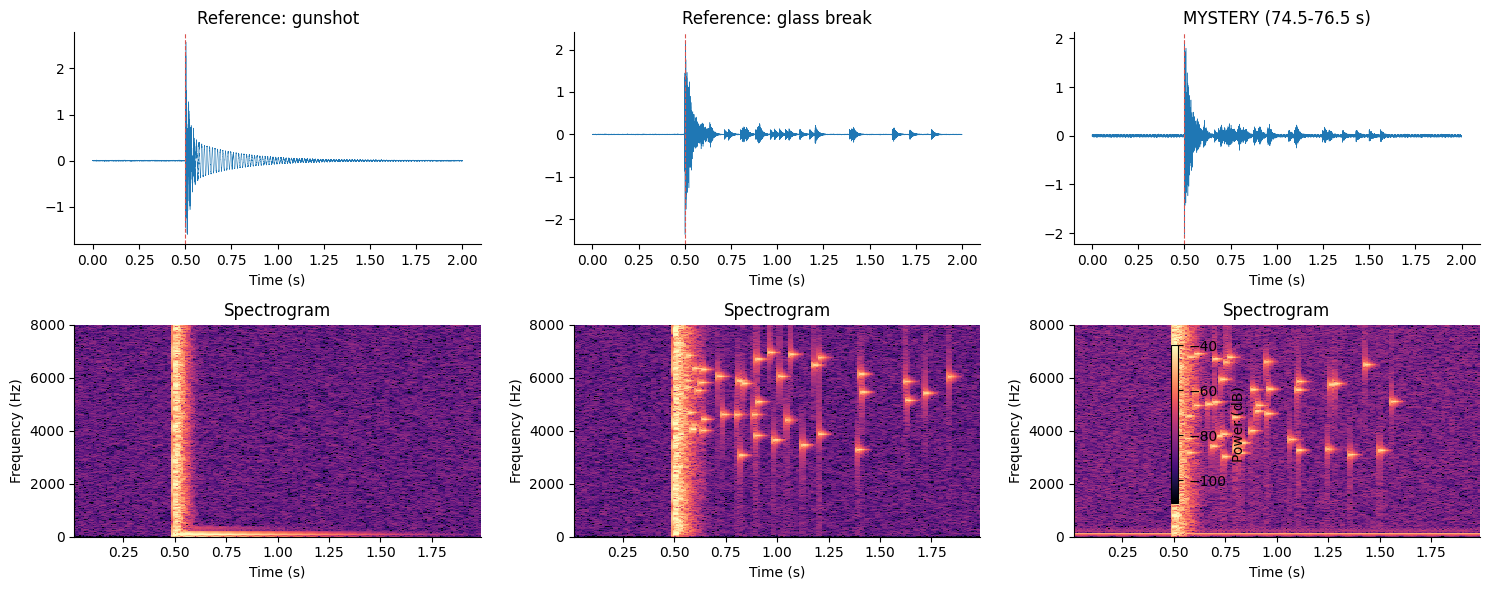

Reference: gunshot: high-frequency energy fraction = 0.003
Reference: glass break: high-frequency energy fraction = 0.990
MYSTERY (74.5-76.5 s): high-frequency energy fraction = 0.872
VERDICT: The mystery sound is most consistent with breaking glass.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for col, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    axes[0, col].plot(t_clip, clip, lw=0.35)
    axes[0, col].axvline(0.5, color="#D9534F", ls="--", lw=0.8)
    axes[0, col].set_title(name); axes[0, col].set_xlabel("Time (s)")
    f, tt, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    spec_db = 10 * np.log10(Sxx + 1e-12)
    pcm = axes[1, col].pcolormesh(tt, f, spec_db, shading="auto", cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_title("Spectrogram")
fig.colorbar(pcm, ax=axes[1, :], label="Power (dB)", shrink=0.75)
plt.tight_layout(); plt.show()

# TODO 3: fraction of spectral energy above 3 kHz, 0.2-1.2 s after impact
hf_fraction = {}
for name, clip in clips.items():
    start, end = int(0.7 * FS), int(1.7 * FS)  # impact at 0.5 s; analyse +0.2 to +1.2 s
    segment = clip[start:end]
    freqs, _, power = signal.spectrogram(segment, fs=FS, nperseg=512, noverlap=384)
    total = power.sum()
    hf_fraction[name] = float(power[freqs > 3000].sum() / total) if total > 0 else 0.0

for name, fraction in hf_fraction.items():
    print(f"{name}: high-frequency energy fraction = {fraction:.3f}")

# TODO 4: verdict based on reference comparison
gun = hf_fraction["Reference: gunshot"]
glass = hf_fraction["Reference: glass break"]
unknown = hf_fraction["MYSTERY (74.5-76.5 s)"]
verdict = "breaking glass" if abs(unknown - glass) < abs(unknown - gun) else "gunshot"
print(f"VERDICT: The mystery sound is most consistent with {verdict}.")

**Reflection:**

No. Waveforms show amplitude over time, so both sounds can appear as a sharp transient and cannot be reliably distinguished by loudness or shape alone. A spectrogram adds three dimensions: **time, frequency, and magnitude**. The deciding pattern is the scattered high-frequency specks / short ringing components that persist after the impact in the glass reference and mystery recording, unlike the gunshot's rapid broadband decay.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

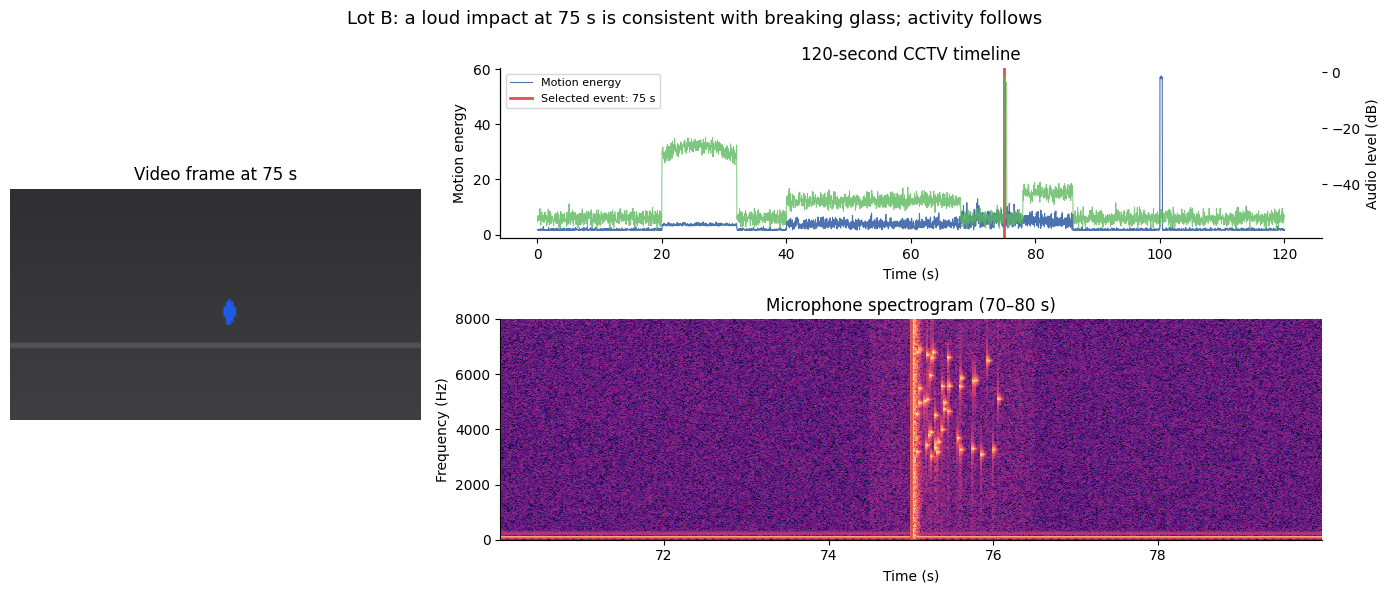

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
ax_frame = fig.add_subplot(gs[:, 0])
ax_timeline = fig.add_subplot(gs[0, 1])
ax_spec = fig.add_subplot(gs[1, 1])

# TODO 1: rendered video frame at t = 75 s
frame_idx = int(round(t_sel * FPS))
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.axis("off")
ax_frame.set_title(f"Video frame at {t_sel:.0f} s")

# TODO 2: full motion + audio timeline with selected-time marker
ax_timeline.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8, label="Motion energy")
ax_timeline.set_ylabel("Motion energy")
ax_audio = ax_timeline.twinx()
ax_audio.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7, alpha=0.8, label="Audio level")
ax_audio.set_ylabel("Audio level (dB)")
ax_timeline.axvline(t_sel, color="#D9534F", lw=2, label="Selected event: 75 s")
ax_timeline.set_title("120-second CCTV timeline")
ax_timeline.set_xlabel("Time (s)")
ax_timeline.legend(loc="upper left", fontsize=8)

# TODO 3: spectrogram of 70–80 s audio with the same marker
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12),
                   shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_spec.axvline(t_sel, color="#D9534F", lw=2)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Microphone spectrogram (70–80 s)")

# TODO 4: conclusion-style title
fig.suptitle("Lot B: a loud impact at 75 s is consistent with breaking glass; activity follows", fontsize=13)
plt.tight_layout(); plt.show()

**Reflection:**

A +2 s audio offset would pair the 75 s video frame with sound recorded at 77 s, so the bang could be attributed to the wrong visual action. The timeline and spectrogram panels would expose the mismatch because their event peaks would not align at the shared 75 s marker. Correct synchronization is essential before drawing cross-modal conclusions.

**Final briefing note:**

At approximately 75 s, Lot B records a sharp impact whose time–frequency signature is more consistent with breaking glass than a gunshot; subsequent movement and elevated activity should be reviewed around the later timeline events. I would put the synchronized video–timeline–spectrogram view first because it links the frame, event timing, and audio signature through a common time reference, while the spectrogram adds frequency evidence that a waveform alone cannot provide. The uncompressed 400-camera estimate is extremely large, so the team should use a tested, risk-based recording policy with efficient encoding and selective retention rather than assuming every stream must remain full-resolution indefinitely. Any reduction in resolution or frame rate must preserve the original evidence around critical incidents, especially fine spatial detail and brief temporal events; retain the original high-quality segment for incident windows.